# Segmentation de vêtements par l'API Hugging Face — corrigé

**Contexte.** Une agence de marketing de mode veut repérer automatiquement les vêtements portés sur des photos
d'influenceurs. Première brique : la *segmentation*, qui attribue à chaque pixel une classe (haut, pantalon, sac,
cheveux, fond…). On teste un modèle déjà entraîné, `sayeed99/segformer_b3_clothes`, appelé par l'**API serverless**
de Hugging Face : pas de serveur à gérer, on envoie une image, on reçoit les masques.

**Les deux questions de la mission**
1. Le modèle segmente-t-il correctement les vêtements des 50 photos annotées fournies ?
2. Combien coûterait le traitement de 500 000 images en 30 jours ?

**Plan du notebook** (une section par étape de l'énoncé)

| § | Étape | Ce qu'on montre |
|---|---|---|
| 1 | Environnement | versions des bibliothèques, projet reproductible |
| 2 | Token | lecture sécurisée depuis `.env`, jamais affiché |
| 3 | Données | 50 images + 50 masques annotés, 18 classes |
| 4 | Appel à l'API | une image pas à pas, puis le script complet (timeout, quota, nouvelles tentatives) |
| 5 | Visualisation | photo / annotation / prédiction côte à côte |
| 6 | Évaluation | IoU et Dice, intervalle de confiance, règle de décision, **fuite de données** |
| 7 | Validation | comment constituer train / validation / test pour la suite |
| 8 | Chiffrage | 500 000 images en 30 jours, trois façons de payer |
| 9 | Conclusion | réponse à la directrice IA |

> Les appels réels à l'API ont été faits une fois par `00_collecte_api.ipynb` et mis en cache dans
> `data/processed/`. Ce notebook relit ce cache : il se ré-exécute sans token et donne toujours les mêmes chiffres.

## 1. Environnement de travail

In [1]:
import sys
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from segvet import api, cache, cost, evaluation as ev, io, viz
from segvet.labels import CLASSES, FRENCH
from segvet.masks import combine_masks

viz.apply_style()
pd.set_option("display.precision", 3)
print("Python", sys.version.split()[0])
for lib in ["requests", "pillow", "numpy", "matplotlib", "pandas", "python-dotenv"]:
    print(f"{lib:<14} {version(lib)}")

Python 3.12.15
requests       2.34.2
pillow         13.0.0
numpy          2.5.4
matplotlib     3.11.2
pandas         3.1.0
python-dotenv  1.2.4


Le projet est un projet `uv` : `pyproject.toml` liste les dépendances, `uv.lock` fige leurs versions exactes.
`uv sync --frozen` recrée le même environnement sur n'importe quelle machine. L'énoncé demandait requests,
Pillow, Matplotlib et NumPy ; pandas sert aux tableaux de résultats, python-dotenv à lire le token.

## 2. Token Hugging Face : un secret qui ne sort jamais du fichier `.env`

Le token donne accès au compte (et à sa facturation). Trois règles :
1. il vit dans un fichier `.env` à la racine du projet (`HF_TOKEN=hf_...`), **listé dans `.gitignore`** ;
2. le code le lit avec `python-dotenv`, il n'apparaît jamais en clair dans le code ni dans une sortie ;
3. on le crée avec le minimum de droits (ici : « appeler les Inference Providers », rien d'autre).

La fonction `api.load_token()` lit le fichier ; `api.check_token()` fait une requête simple qui renvoie le nom du
compte. On vérifie ci-dessous, **sans l'afficher**, que le token est bien hors de portée de git.

In [2]:
import subprocess

env_file = io.PROJECT_DIR / ".env"
ignored = subprocess.run(["git", "check-ignore", "-q", str(env_file)], cwd=io.PROJECT_DIR).returncode == 0
print(f".env présent : {env_file.exists()} ; ignoré par git : {ignored}")
print("Exemple versionné à la place :", (io.PROJECT_DIR / ".env.example").read_text().splitlines()[-1])

.env présent : True ; ignoré par git : True
Exemple versionné à la place : HF_TOKEN=hf_xxxxxxxxxxxxxxxxxxxxxxxxxxxxxxxx


## 3. Les données de test

In [3]:
pairs = io.load_pairs()
sizes = pd.Series([Image.open(img).size for img, _ in pairs]).value_counts()
print(f"{len(pairs)} couples image / masque annoté")
print("Tailles (largeur, hauteur) :", sizes.to_dict())

truths = [io.read_mask(mask) for _, mask in pairs]
pixels = np.bincount(np.concatenate([t.ravel() for t in truths]), minlength=len(CLASSES))
presence = np.array([[c in np.unique(t) for c in range(len(CLASSES))] for t in truths]).sum(axis=0)
classes = pd.DataFrame(
    {"classe": [FRENCH[c] for c in CLASSES], "images": presence, "part des pixels (%)": 100 * pixels / pixels.sum()},
    index=pd.Index(range(len(CLASSES)), name="id"),
)
classes

50 couples image / masque annoté
Tailles (largeur, hauteur) : {(400, 600): 46, (97, 412): 1, (397, 600): 1, (400, 582): 1, (400, 640): 1}


,classe,images,part des pixels (%)
id,,,
0,Fond,50,78.360
1,Chapeau,13,0.294
2,Cheveux,46,1.792
3,Lunettes de soleil,13,0.067
4,Haut,41,6.741
5,Jupe,10,0.827
6,Pantalon,35,3.825
7,Robe,13,2.424
8,Ceinture,10,0.067


**Ce qu'on retient des données**
- 50 photos de plain-pied, presque toutes en 400 × 600 px. Une seule est très étroite (97 × 412) ; le code ne
  suppose aucune taille fixe.
- Chaque masque est une image en niveaux de gris où la valeur d'un pixel **est** l'identifiant de sa classe
  (0 = fond, 4 = haut, 6 = pantalon…), dans la même numérotation que le modèle.
- Le fond occupe **78 % des pixels**. Les vêtements fins sont minuscules : ceinture et lunettes font chacune
  0,07 % des pixels. L'écharpe n'apparaît que sur 3 images : impossible de juger le modèle sur elle.

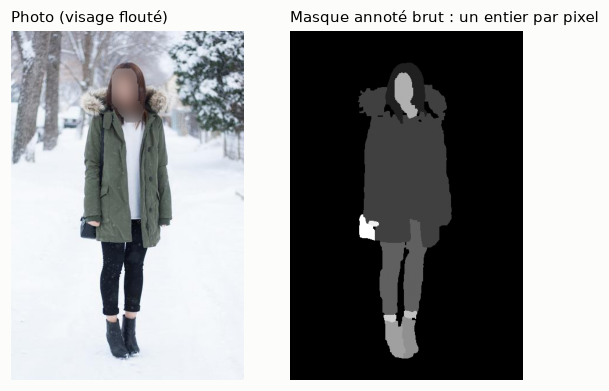

Valeurs présentes dans ce masque : [0, 2, 4, 6, 9, 10, 11, 12, 13, 15, 16]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(6, 4.2))
image, mask = pairs[0]
axes[0].imshow(viz.blur_faces(np.array(Image.open(image).convert("RGB")), truths[0]))
axes[0].set_title("Photo (visage flouté)", fontsize=10, fontweight="normal")
axes[1].imshow(truths[0], cmap="gray")
axes[1].set_title("Masque annoté brut : un entier par pixel", fontsize=10, fontweight="normal")
for ax in axes:
    ax.axis("off")
plt.show()
print("Valeurs présentes dans ce masque :", np.unique(truths[0]).tolist())

## 4. Appeler le modèle par l'API

### 4.1 Une requête, pas à pas

| Élément | Valeur |
|---|---|
| Adresse | `https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes` |
| Méthode | `POST`, le corps de la requête = les octets de l'image |
| En-têtes | `Authorization: Bearer <token>` et `Content-Type: image/jpeg` |
| Réponse | une liste JSON : pour chaque classe détectée, `label`, `score` et `mask` (une image PNG encodée en base64) |

⚠️ Le notebook fourni avec l'énoncé utilise l'adresse `api-inference.huggingface.co/models/...` : elle n'est plus
en service depuis 2025, Hugging Face l'a remplacée par le routeur `router.huggingface.co`.

Voici la fonction minimale, celle qu'un apprenant écrit en une vingtaine de lignes. Elle n'est **pas appelée** ici
(pas de token nécessaire pour relire le corrigé) ; le script complet est `segvet.api.SegformerClient`.

In [5]:
import requests

API_URL = "https://router.huggingface.co/hf-inference/models/sayeed99/segformer_b3_clothes"


def segmenter(image_path, token, timeout=30):
    """Envoie une image au modèle et renvoie la liste des masques (label, score, mask en base64)."""
    with open(image_path, "rb") as f:
        data = f.read()
    headers = {"Authorization": f"Bearer {token}", "Content-Type": "image/png"}
    response = requests.post(API_URL, headers=headers, data=data, timeout=timeout)
    response.raise_for_status()  # lève une erreur si le code HTTP n'est pas 2xx
    return response.json()

Une réponse réelle de l'API a été conservée (`data/processed/exemple_reponse_api.json`). Regardons-la : un
élément par classe détectée, et chaque masque est une petite image PNG en noir et blanc, encodée en texte (base64).

In [6]:
import json

example = json.loads((cache.PROCESSED_DIR / "exemple_reponse_api.json").read_text())
print(f"{len(example['response'])} classes détectées sur {example['image']}")
for item in example["response"][:4]:
    print(f"  {item['label']:<14} score={item['score']}  mask='{item['mask'][:30]}…' ({len(item['mask'])} caractères)")

size = Image.open(io.IMAGES_DIR / example["image"]).size
label_map = combine_masks(example["response"], size)
print("Carte de classes reconstituée :", label_map.shape, "valeurs", np.unique(label_map).tolist())

11 classes détectées sur image_0.png
  Background     score=1  mask='iVBORw0KGgoAAAANSUhEUgAAAVUAAA…' (2796 caractères)
  Hair           score=1  mask='iVBORw0KGgoAAAANSUhEUgAAAVUAAA…' (1160 caractères)
  Upper-clothes  score=1  mask='iVBORw0KGgoAAAANSUhEUgAAAVUAAA…' (1888 caractères)
  Pants          score=1  mask='iVBORw0KGgoAAAANSUhEUgAAAVUAAA…' (1100 caractères)
Carte de classes reconstituée : (600, 400) valeurs [0, 2, 4, 6, 9, 10, 11, 12, 13, 15, 16]


L'API ne renvoie pas une image segmentée, mais **une liste de masques, un par classe détectée** ; il faut les
décoder (base64 → PNG → tableau NumPy) puis les fusionner en une seule carte où chaque pixel porte l'identifiant
de sa classe. C'est le rôle de `combine_masks`, qui ramène aussi chaque masque à la taille de l'image d'origine au
**plus proche voisin** (une interpolation lisse inventerait des classes intermédiaires). Deux différences avec le
notebook fourni : un label inconnu lève une erreur au lieu d'être rangé en silence dans le fond, et le fond ne
peut jamais écraser un vêtement.

### 4.2 Le script complet : ce qui distingue un script qui marche d'un script fiable

| Risque | Parade dans `SegformerClient` | Réglage |
|---|---|---|
| Le serveur ne répond pas | `timeout` sur chaque requête | 30 s |
| Dépasser le quota | limiteur : jamais plus de N requêtes sur une minute glissante | 30 / min |
| Modèle en cours de chargement (503), quota (429), panne passagère | nouvelles tentatives, attente qui double (2, 4, 8, 16 s) ou durée imposée par `Retry-After` | 4 |
| Token faux (401), crédits épuisés (402), droits (403) | arrêt immédiat avec un message clair : réessayer ne changerait rien | — |
| Images lourdes | réduction à 512 px de côté et JPEG qualité 90 : le modèle travaille de toute façon en 512 × 512 | — |
| Une image échoue au milieu de 50 | l'erreur est journalisée, la boucle continue ; relancer ne refait que les manquantes | — |

Toutes ces protections sont vérifiées par des tests (`tests/test_api.py`) contre une fausse API : 503 puis succès,
429 avec `Retry-After`, timeout, 401 non relancé, quota jamais dépassé.

In [7]:
logs = {variant: cache.read_log(variant) for variant in cache.VARIANTS}
for variant, log in logs.items():
    ok = log["status"].eq(200)
    print(
        f"{variant:>8} : {ok.sum()} succès / {len(log)} ; tentatives > 1 : {(log['attempts'] > 1).sum()} ; "
        f"octets envoyés (médiane) : {log['bytes_sent'].median() / 1000:.0f} Ko"
    )

 jpeg512 : 50 succès / 50 ; tentatives > 1 : 0 ; octets envoyés (médiane) : 53 Ko
     png : 50 succès / 50 ; tentatives > 1 : 0 ; octets envoyés (médiane) : 426 Ko
jpeg_pleine_taille : 50 succès / 50 ; tentatives > 1 : 0 ; octets envoyés (médiane) : 61 Ko


Les 150 appels (50 images × 3 variantes d'envoi) ont tous réussi du premier coup : ni quota dépassé, ni modèle en
cours de chargement. Les protections du client n'ont donc pas eu à servir ici ; elles restent indispensables à
500 000 images, où une panne passagère est certaine. En JPEG réduit à 512 px, une image pèse environ 53 Ko.

## 5. Visualiser les résultats

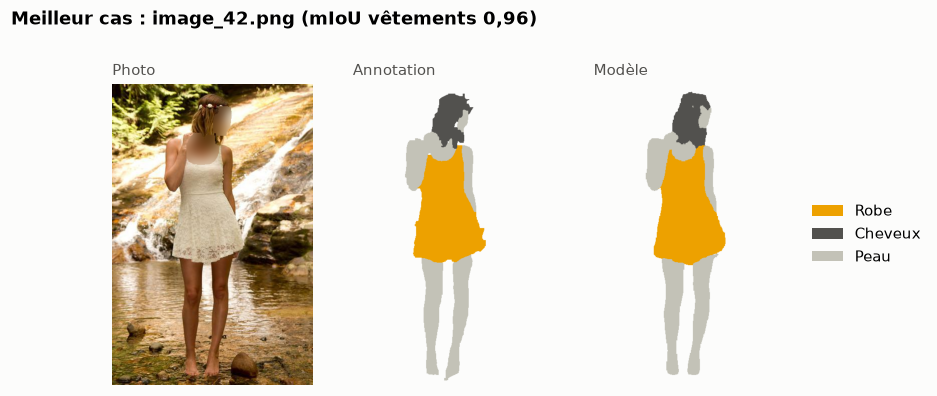

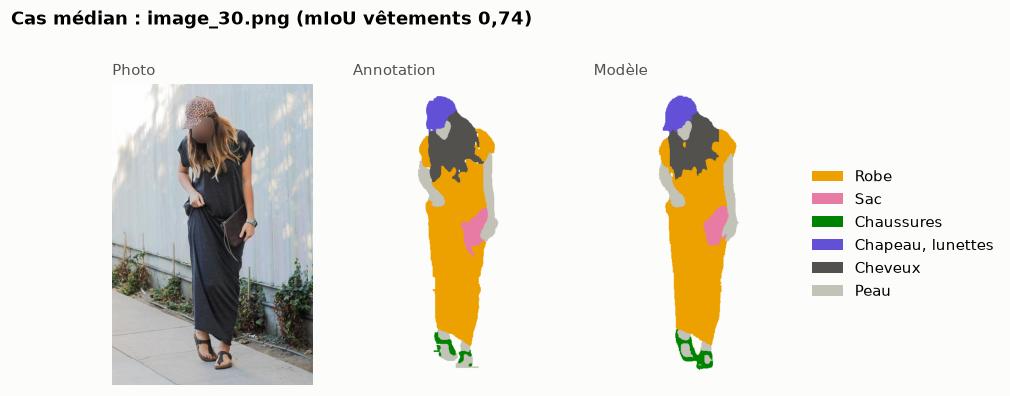

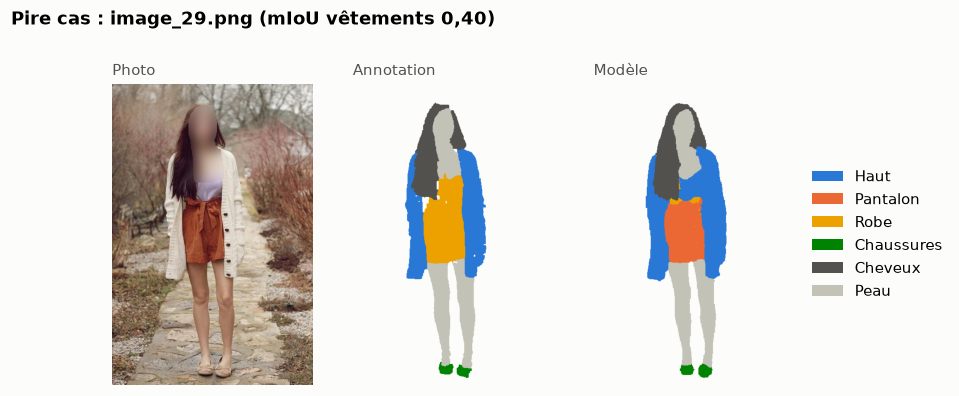

In [8]:
preds = [cache.read_prediction(img, "jpeg512") for img, _ in pairs]
preds_png = [cache.read_prediction(img, "png") for img, _ in pairs]
preds_full = [cache.read_prediction(img, "jpeg_pleine_taille") for img, _ in pairs]
photos = [np.array(Image.open(img).convert("RGB")) for img, _ in pairs]
cms = ev.image_confusions(truths, preds)
cms_png = ev.image_confusions(truths, preds_png)
cms_full = ev.image_confusions(truths, preds_full)

per_image = pd.Series(ev.per_image_clothing_miou(cms), index=[img.name for img, _ in pairs], name="mIoU vêtements")
order = per_image.sort_values()
examples = {"Meilleur cas": order.index[-1], "Cas médian": order.index[len(order) // 2], "Pire cas": order.index[0]}
names = [img.name for img, _ in pairs]
for label, name in examples.items():
    i = names.index(name)
    fig, axes = plt.subplots(1, 3, figsize=(8, 4.2))
    title = f"{label} : {name} (mIoU vêtements {viz.fr(per_image[name])})"
    viz.show_triptych(photos[i], truths[i], preds[i], title, axes)
    slug = {"Meilleur cas": "meilleur", "Cas médian": "median", "Pire cas": "pire"}[label]
    viz.save(fig, f"triptyque_{slug}_{name.removesuffix('.png')}")
    plt.show()

**Lecture des exemples.** Le meilleur cas (robe simple, fond dégagé) est presque parfait. Les moins bons ne sont
pas des échecs grossiers mais des **vêtements ambigus** : sur l'image 29, un short est annoté « robe » et prédit
« pantalon » ; sur l'image 31, une tunique sur un collant est annotée « robe » et prédite « haut ». Le contour de la
personne, le sac et les chaussures sont justes. Pour ModeTrends, cela pose une question de **définition des
classes** (où s'arrête un haut, où commence une robe ?) autant qu'une question de modèle.

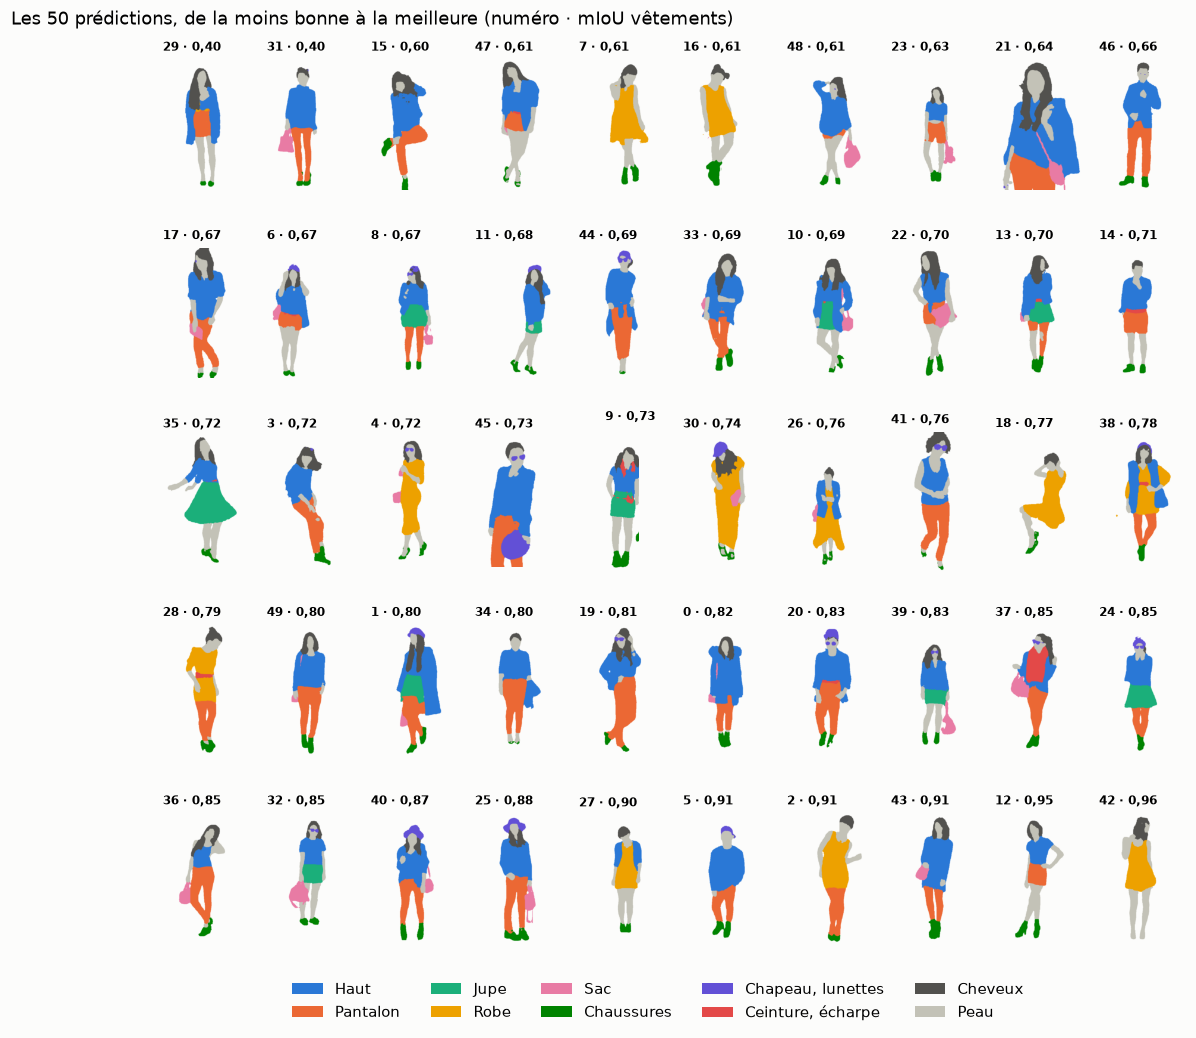

In [9]:
fig, axes = plt.subplots(5, 10, figsize=(12, 9.5))
for ax, i in zip(axes.flat, order.index.map(names.index)):
    ax.imshow(viz.colorize(preds[i]))
    ax.set_title(f"{names[i].removeprefix('image_').removesuffix('.png')} · {viz.fr(per_image.iloc[i])}", fontsize=8)
    ax.axis("off")
fig.suptitle("Les 50 prédictions, de la moins bonne à la meilleure (numéro · mIoU vêtements)", x=0.01, ha="left")
fig.subplots_adjust(top=0.94, bottom=0.08, hspace=0.3)
fig.legend(handles=viz.legend_handles(*preds), loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0))
viz.save(fig, "mosaique_50_predictions")
plt.show()

## 6. Évaluer le modèle

### 6.1 Pourquoi pas « le pourcentage de pixels bien classés » ?

In [10]:
from segvet.metrics import pixel_accuracy

total = cms.sum(axis=0)
all_background = sum(ev.image_confusions(truths, [np.zeros_like(t) for t in truths]))
print(f"Exactitude par pixel du modèle                 : {pixel_accuracy(total):.3f}")
print(f"Exactitude d'un « modèle » qui ne prédit que du fond : {pixel_accuracy(all_background):.3f}")

Exactitude par pixel du modèle                 : 0.960
Exactitude d'un « modèle » qui ne prédit que du fond : 0.784


96 % de pixels bien classés, cela paraît excellent… mais un « modèle » qui répond « fond » partout atteint déjà 78 %
sans reconnaître un seul vêtement. Quand une classe domine, l'exactitude par pixel récompense surtout le fond : on
mesure donc chaque classe séparément.

### 6.2 IoU et Dice par famille de vêtements

- **IoU** (*Intersection over Union*) = pixels communs à l'annotation et à la prédiction ÷ pixels couverts par
  l'une ou l'autre. 1 = superposition parfaite, 0 = aucun pixel commun.
- **Dice** = 2 × pixels communs ÷ (pixels annotés + pixels prédits) : c'est le F1 calculé au niveau du pixel.
  Il se déduit de l'IoU (Dice = 2 IoU / (1 + IoU)) : même classement, valeurs un peu plus hautes.

Choix du `PLAN.md` : les pixels des 50 images sont cumulés dans une seule matrice de confusion avant le calcul
(une classe minuscule dans une image ne pèse pas autant qu'un manteau entier) ; gauche et droite sont fusionnées
(chaussures, bras, jambes) ; la **métrique principale** est le **mIoU vêtements** = moyenne des IoU des 9 familles
de vêtements présentes dans au moins 5 images. L'écharpe (3 images) est publiée à part.

In [11]:
table = ev.per_class_table(cms)
table["groupe"] = np.where(table.index.isin(ev.CLOTHING), "vêtement (métrique principale)",
                           np.where(table.index == "Écharpe", "vêtement (trop rare : à part)", "corps / fond"))
table.sort_values(["groupe", "iou"], ascending=[False, False])

,iou,dice,images,pixels_annotes,groupe
famille,,,,,
Écharpe,0.825,0.904,3,14658,vêtement (trop rare : à part)
Jupe,0.942,0.970,10,97649,vêtement (métrique principale)
Pantalon,0.899,0.947,35,451597,vêtement (métrique principale)
Haut,0.881,0.936,41,795898,vêtement (métrique principale)
Chapeau,0.848,0.918,13,34752,vêtement (métrique principale)
Robe,0.801,0.889,13,286217,vêtement (métrique principale)
Chaussures,0.754,0.860,47,118116,vêtement (métrique principale)
Sac,0.726,0.841,24,73374,vêtement (métrique principale)
Lunettes,0.702,0.825,13,7933,vêtement (métrique principale)


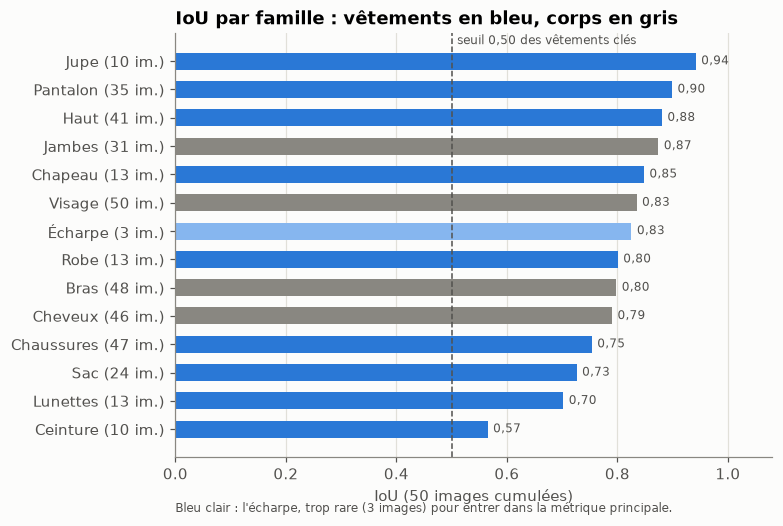

In [12]:
shown = table.drop(index="Fond").sort_values("iou")
fig, ax = plt.subplots(figsize=(7, 5))
colors = [viz.BLUE if g in ev.CLOTHING else viz.LIGHT_BLUE if g == "Écharpe" else viz.MUTED for g in shown.index]
ax.barh([f"{g} ({n} im.)" for g, n in zip(shown.index, shown["images"])], shown["iou"], color=colors, height=0.6)
ax.axvline(ev.KEY_FLOOR, color=viz.TEXT_2, lw=1, ls="--")
ax.text(ev.KEY_FLOOR + 0.01, len(shown) - 0.4, "seuil 0,50 des vêtements clés", fontsize=8, color=viz.TEXT_2)
for y, v in enumerate(shown["iou"]):
    ax.text(v + 0.01, y, viz.fr(v), va="center", fontsize=8, color=viz.TEXT_2)
ax.set_xlim(0, 1.08)
ax.set_xlabel("IoU (50 images cumulées)")
ax.set_title("IoU par famille : vêtements en bleu, corps en gris")
ax.text(0, -0.13, "Bleu clair : l'écharpe, trop rare (3 images) pour entrer dans la métrique principale.",
        transform=ax.transAxes, fontsize=8, color=viz.TEXT_2)
ax.grid(axis="y", visible=False)
viz.save(fig, "iou_par_famille")
plt.show()

**Lecture.** Les grandes pièces sont bien segmentées : jupe 0,94, pantalon 0,90, haut 0,88. Les petits objets à
contours fins le sont moins : sac 0,73, lunettes 0,70 et surtout **ceinture 0,57**. Explication probable, au moins en
partie : pour une ceinture de quelques pixels de large, un décalage d'un ou deux pixels sur le bord suffit à faire
chuter l'IoU (la fiche 6 le montre). Le corps (jambes 0,87,
visage 0,83) est du même ordre que les vêtements.

### 6.3 Un intervalle de confiance, et la règle de décision fixée avant de voir les résultats

50 images, c'est peu : un autre lot de 50 photos aurait donné un autre chiffre. Le **bootstrap** estime cette
variabilité : on tire 50 images *avec remise* parmi les 50, on recalcule le mIoU vêtements, 2 000 fois ; les 2,5 %
et 97,5 % des valeurs obtenues bornent l'intervalle à 95 %.

Règle écrite dans le `PLAN.md` **avant** les résultats : « non disqualifié pour un pilote » si la borne basse de
l'intervalle est ≥ 0,60 **et** si haut, pantalon, robe, jupe et chaussures ont chacun un IoU ≥ 0,50 ; sinon
« insuffisant ».

In [13]:
boot = ev.bootstrap(cms, n_boot=2000, seed=0, others=cms_png)
low, high = boot["ci"]
verdict, weak = ev.decision(low, table)
print(f"mIoU vêtements : {boot['estimate']:.3f}  (IC 95 % : {low:.3f} – {high:.3f})")
print(f"Tirages où une famille de vêtements disparaît : {boot['degenerate_share']:.1%}")
print(f"mIoU 18 classes (annexe) : {np.nanmean(ev.iou_per_class(total)):.3f}")
print(f"Vêtements clés sous 0,50 : {weak or 'aucun'}")
print(f"Verdict de la règle : {verdict}")

iou18 = pd.Series(ev.iou_per_class(total), index=[FRENCH[c] for c in CLASSES])
print("IoU gauche / droite séparés :", iou18[["Chaussure gauche", "Chaussure droite", "Jambe gauche", "Jambe droite",
                                           "Bras gauche", "Bras droit"]].round(2).to_dict())
right_shoe = total[CLASSES.index("Right-shoe")]
print(f"Pixels de chaussure droite prédits « gauche » : {right_shoe[CLASSES.index('Left-shoe')] / right_shoe.sum():.0%}")

mIoU vêtements : 0.791  (IC 95 % : 0.756 – 0.818)
Tirages où une famille de vêtements disparaît : 0.0%
mIoU 18 classes (annexe) : 0.645
Vêtements clés sous 0,50 : aucun
Verdict de la règle : non disqualifié pour un pilote
IoU gauche / droite séparés : {'Chaussure gauche': 0.31, 'Chaussure droite': 0.2, 'Jambe gauche': 0.42, 'Jambe droite': 0.22, 'Bras gauche': 0.34, 'Bras droit': 0.33}
Pixels de chaussure droite prédits « gauche » : 59%


**mIoU vêtements = 0,79, intervalle à 95 % de 0,76 à 0,82.** Aucune famille de vêtements ne disparaît des tirages
(chacune est présente dans au moins 10 images). La borne basse (0,76) dépasse le seuil de 0,60 et aucun vêtement
clé n'est sous 0,50 : selon la règle fixée à l'avance, le modèle est **« non disqualifié pour un pilote »**.

Le mIoU sur les 18 classes (0,65) est plus bas, parce qu'il compte séparément gauche et droite, et le modèle les
distingue mal : chaussures, jambes et bras ont des IoU de 0,20 à 0,42 quand on sépare les côtés, contre 0,75 à 0,87
quand on les fusionne. Pour la chaussure droite de la personne, il se trompe même plus souvent qu'il n'a raison
(59 % de ses pixels sont prédits « gauche »). Hypothèse possible, non vérifiée : un entraînement avec des images
retournées en miroir sans échanger les étiquettes gauche et droite. Pour une marque, l'erreur est sans importance :
d'où le choix, fait avant les résultats, de fusionner gauche et droite.

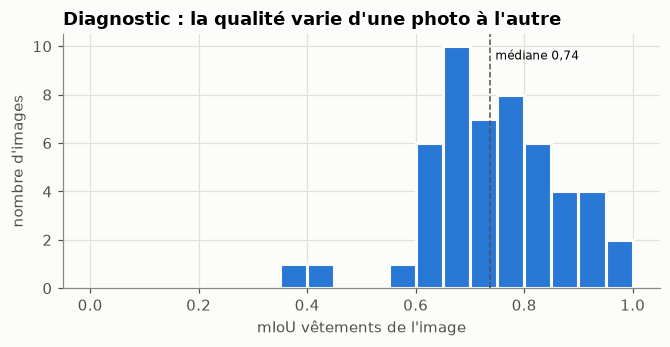

count    50.000
mean      0.745
std       0.121
min       0.395
25%       0.676
50%       0.737
75%       0.833
max       0.964
Name: mIoU vêtements, dtype: float64

In [14]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(per_image, bins=np.arange(0, 1.05, 0.05), color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=2)
ax.axvline(per_image.median(), color=viz.TEXT_2, lw=1, ls="--")
ax.text(per_image.median() + 0.01, ax.get_ylim()[1] * 0.9, f"médiane {viz.fr(per_image.median())}", fontsize=8)
ax.set_xlabel("mIoU vêtements de l'image")
ax.set_ylabel("nombre d'images")
ax.set_title("Diagnostic : la qualité varie d'une photo à l'autre")
viz.save(fig, "distribution_par_image")
plt.show()
per_image.describe()

La moitié des images ont un mIoU vêtements entre 0,68 et 0,83 ; deux images descendent à 0,40, ce sont les deux
vêtements ambigus vus plus haut. Le mIoU par image sert au **diagnostic** (trouver les cas à regarder) ; il est trop
sensible aux toutes petites zones pour servir de métrique principale.

### 6.4 ⚠️ Ces 50 images, le modèle les a déjà vues

Le modèle a été affiné sur un jeu public, `mattmdjaga/human_parsing_dataset` (ATR, 17 706 photos annotées). En
comparant les masques pixel à pixel, on retrouve **les 50 masques de test, à l'identique**, dans ce jeu. Le code
d'entraînement publié par l'auteur de cette famille de modèles ne réserve que 0,6 % des images au test : on s'attend
donc à ce que 49 ou 50 de nos images aient servi à l'entraînement.

C'est un examen dont l'élève connaissait les questions. Conséquences :
- les chiffres ci-dessus sont une **performance sur des images vues à l'entraînement : une estimation optimiste,
  qui ne mesure pas la généralisation** à de nouvelles photos d'influenceurs ;
- un mauvais score aurait été très informatif (le modèle échoue même sur ce qu'il a appris) ; un bon score l'est peu ;
- la fiche du modèle annonce ses propres IoU, mesurés sur ses 0,6 % d'images de test : la comparaison avec nos
  chiffres reste **qualitative** (autre échantillon, autre prétraitement).

La vérification (téléchargement de 800 Mo) n'est pas rejouée ici ; le script figure dans la fiche pédagogique 7.

In [15]:
model_card = pd.Series(
    {"Chapeau": 0.68, "Lunettes": 0.63, "Haut": 0.78, "Jupe": 0.65, "Pantalon": 0.84, "Robe": 0.55,
     "Ceinture": 0.30, "Sac": 0.84, "Écharpe": 0.29},
    name="IoU fiche du modèle",
)
comparison = pd.concat([model_card, table["iou"].rename("IoU sur nos 50 images")], axis=1).dropna()
comparison

,IoU fiche du modèle,IoU sur nos 50 images
Chapeau,0.68,0.848
Lunettes,0.63,0.702
Haut,0.78,0.881
Jupe,0.65,0.942
Pantalon,0.84,0.899
Robe,0.55,0.801
Ceinture,0.30,0.565
Sac,0.84,0.726
Écharpe,0.29,0.825


Nos IoU sont plus élevés que ceux de la fiche du modèle pour presque toutes les classes. L'écart le plus frappant,
c'est l'écharpe : 0,83 chez nous contre 0,29 dans la fiche, mais sur 3 images seulement, c'est aussi le moins
informatif. On pourrait croire que le modèle va mieux que prévu.
Mais c'est plutôt ce qu'on attend d'un modèle **interrogé sur des images qu'il a appris par cœur**. Seul le sac fait
moins bien (0,73 contre 0,84). Ces chiffres ne permettent donc pas de dire que le modèle « convient » aux photos de
ModeTrends : il faudra le tester sur des photos jamais vues (§ 7).

### 6.5 Alléger les images coûte-t-il en qualité ?

Chaque image a aussi été envoyée en PNG d'origine, le fichier tel quel. On compare le mIoU vêtements des deux
variantes **sur les mêmes images** (bootstrap apparié : chaque tirage recalcule les deux variantes sur les mêmes
images) ; marge fixée avant de voir les résultats : |Δ| < 0,01.

In [16]:
d_low, d_high = boot["delta_ci"]
size_ratio = logs["png"]["bytes_sent"].median() / logs["jpeg512"]["bytes_sent"].median()
print(f"mIoU vêtements JPEG 512 : {boot['estimate']:.4f} ; PNG d'origine : {ev.clothing_miou(cms_png.sum(axis=0)):.4f}")
print(f"Δ (JPEG − PNG) = {boot['delta']:+.4f}  (IC 95 % apparié : {d_low:+.4f} – {d_high:+.4f})")
print(f"Équivalence (IC entièrement dans ±0,01) : {-0.01 < d_low and d_high < 0.01}")
print(f"Poids médian envoyé : PNG {size_ratio:.1f} fois plus lourd que le JPEG 512")
for variant in ["jpeg512", "png"]:
    s = logs[variant].query("attempts == 1")["seconds"]
    print(f"Latence {variant:>7} : médiane {s.median():.2f} s, 95e centile {s.quantile(0.95):.2f} s")

# La borne de l'intervalle dépend du tirage aléatoire : on regarde 6 graines
bounds = [ev.bootstrap(cms, n_boot=2000, seed=k, others=cms_png)["delta_ci"] for k in range(6)]
print("Bornes de l'IC du Δ selon la graine (0 à 5) :", [f"{lo:+.4f} / {hi:+.4f}" for lo, hi in bounds])

fam_jpeg, fam_png = ev.per_class_table(cms)["iou"], ev.per_class_table(cms_png)["iou"]
print("Δ IoU par famille (JPEG − PNG) :", (fam_jpeg - fam_png)[ev.CLOTHING].round(3).to_dict())

mIoU vêtements JPEG 512 : 0.7907 ; PNG d'origine : 0.7959
Δ (JPEG − PNG) = -0.0052  (IC 95 % apparié : -0.0099 – -0.0001)
Équivalence (IC entièrement dans ±0,01) : True
Poids médian envoyé : PNG 8.1 fois plus lourd que le JPEG 512
Latence jpeg512 : médiane 0.71 s, 95e centile 1.24 s
Latence     png : médiane 1.02 s, 95e centile 1.48 s


Bornes de l'IC du Δ selon la graine (0 à 5) : ['-0.0099 / -0.0001', '-0.0098 / -0.0002', '-0.0098 / -0.0003', '-0.0096 / -0.0000', '-0.0102 / -0.0004', '-0.0099 / -0.0003']
Δ IoU par famille (JPEG − PNG) : {'Chapeau': -0.009, 'Lunettes': -0.002, 'Haut': -0.006, 'Jupe': -0.002, 'Pantalon': -0.013, 'Robe': -0.004, 'Ceinture': 0.003, 'Chaussures': -0.003, 'Sac': -0.012}


**Lecture.** Le JPEG réduit à 512 px est **8 fois plus léger** que le PNG d'origine et plus rapide (0,71 s en médiane
contre 1,02 s ; l'ordre d'envoi alternait d'une image à l'autre, ce qui limite l'effet d'une variation du réseau).
Il perd 0,005 point de mIoU vêtements. Avec la graine prévue au plan, l'intervalle apparié (de −0,0099 à −0,0001)
tient dans la marge de ±0,01 : la règle conclut à l'**équivalence, mais à la limite**. Selon la graine du tirage, la
borne basse varie de −0,0096 à −0,0102 : un autre tirage aurait pu conclure l'inverse. Ce qu'on retient : une perte
d'environ 0,005, **petite et probablement réelle**, qui touche la marge fixée. Par famille, elle dépasse 0,01 pour
le pantalon et le sac.

**Annexe — l'effet de la seule résolution.** Un premier passage avait envoyé, par erreur, du JPEG en pleine
taille au lieu du PNG prévu. On le garde : comparé au JPEG 512, il isole l'effet de la réduction à 512 px, à
compression égale.

In [17]:
full = ev.bootstrap(cms, n_boot=2000, seed=0, others=cms_full)
f_low, f_high = full["delta_ci"]
print(f"Δ (JPEG 512 − JPEG pleine taille) = {full['delta']:+.4f}  (IC 95 % apparié : {f_low:+.4f} – {f_high:+.4f})")
compression = ev.bootstrap(cms_full, n_boot=2000, seed=0, others=cms_png)
c_low, c_high = compression["delta_ci"]
print(f"Δ (JPEG pleine taille − PNG)  = {compression['delta']:+.4f}  (IC 95 % apparié : {c_low:+.4f} – {c_high:+.4f})")

Δ (JPEG 512 − JPEG pleine taille) = -0.0051  (IC 95 % apparié : -0.0100 – -0.0004)


Δ (JPEG pleine taille − PNG)  = -0.0001  (IC 95 % apparié : -0.0020 – +0.0021)


JPEG 512 contre JPEG pleine taille : même écart (−0,005). JPEG pleine taille contre PNG : aucun écart mesurable.
La petite perte vient donc de la **réduction de résolution**, pas de la compression JPEG. Explication probable
(non testée ici) : l'API renvoie des masques à la taille de l'image reçue ; une image réduite donne des masques moins
fins, qu'on agrandit ensuite, d'où des contours légèrement en escalier. Pour ModeTrends, le compromis reste
favorable (8 fois moins de données pour 0,5 point d'IoU) ; si la précision des contours devenait critique, on
enverrait les images en JPEG pleine taille, qui ne coûte presque rien de plus (61 Ko).

## 7. Méthode de validation pour la suite : train, validation, test

Ici, **rien n'est entraîné** : le modèle est utilisé tel quel, donc les 50 images ne servent qu'à le tester. Le
découpage en trois jeux devient indispensable dès qu'on voudra **affiner** le modèle sur des photos ModeTrends
(par exemple pour ajouter une classe « veste » ou mieux reconnaître les ceintures).

| Jeu | Rôle | Proposition |
|---|---|---|
| Entraînement (≈ 70 %) | le modèle apprend sur ces images | photos ModeTrends annotées |
| Validation (≈ 15 %) | choisir les réglages (nombre d'époques, taux d'apprentissage) et arrêter l'entraînement au bon moment | jamais utilisé pour apprendre |
| Test (≈ 15 %) | mesurer **une seule fois, à la fin**, la performance sur des images jamais vues | mis sous clé dès le début |

Trois précautions, toutes tirées de ce qu'on vient de constater :
1. **Découper par influenceur, pas par photo** : deux photos de la même personne, dans la même tenue, se
   ressemblent trop. Si l'une est en entraînement et l'autre en test, le test redevient un examen dont on connaît
   les questions — exactement la fuite du § 6.4.
2. **Vérifier l'absence de doublons** entre les jeux (empreinte des images), y compris avec les données publiques
   déjà vues par le modèle pré-entraîné.
3. **Un test représentatif** : des photos comme celles que ModeTrends traitera (réseaux sociaux, cadrages variés,
   plusieurs personnes), avec assez d'exemples de chaque vêtement rare (au moins une trentaine d'images par famille).

## 8. Chiffrage : 500 000 images en 30 jours

In [18]:
ok = logs["jpeg512"].query("status == 200 and attempts == 1")
latency = ok["seconds"]
print(f"Latence par image (JPEG 512, {len(ok)} appels sans nouvelle tentative) : "
      f"médiane {latency.median():.2f} s, 95e centile {latency.quantile(0.95):.2f} s")
need = cost.required_rate_per_minute(500_000, 30)
print(f"Débit moyen nécessaire : {need:.1f} images par minute")

Latence par image (JPEG 512, 50 appels sans nouvelle tentative) : médiane 0.71 s, 95e centile 1.24 s
Débit moyen nécessaire : 11.6 images par minute


Une image prend **0,71 s** en médiane entre l'envoi et la réponse, 1,24 s au 95ᵉ centile. Ce temps comprend le
réseau et la file d'attente du service : il **majore** le temps de calcul facturé. Il exclut en revanche les pauses
imposées par notre propre limiteur de débit (un premier passage les comptait par erreur, voir la fiche 8). Le besoin
moyen, **11,6 images par minute**, est modeste : notre client plafonné à 30 requêtes par minute le couvre déjà, à un
seul appel à la fois.

In [19]:
import json

N, DAYS = 500_000, 30
# Facturation réelle lue sur la page « Inference Providers » du compte le 2026-10-24 : 301 requêtes, « < 0,01 $ »
billed_ceiling, n_billed = 0.01, 301
# Grille Hugging Face (Inference Endpoints, AWS), lue le 2026-10-24
CPU_2VCPU_PER_HOUR, T4_PER_HOUR = 0.07, 0.50

bench = json.loads((cache.PROCESSED_DIR / "mesure_inference_locale.json").read_text())
t_local = next(m["median_s"] for m in bench["mesures"] if m["threads"] == 2)
t_cloud = 2 * t_local  # hypothèse prudente : un vCPU cloud deux fois plus lent que le poste de mesure

scenarios = pd.DataFrame(
    [
        ("A. Serverless (hf-inference)", "majorant mesuré : < 0,01 $ pour 301 requêtes",
         cost.serverless_cost(N, 1, billed_ceiling / n_billed), "aucune"),
        ("B. Endpoint CPU 2 vCPU allumé 24 h/24", f"{60 / t_cloud:.0f} images/min estimées",
         cost.dedicated_cost(24 * DAYS, CPU_2VCPU_PER_HOUR), "créer et surveiller l'endpoint"),
        ("B. Endpoint GPU T4 allumé 24 h/24", "large surcapacité", cost.dedicated_cost(24 * DAYS, T4_PER_HOUR),
         "créer et surveiller l'endpoint"),
        ("B'. Endpoint CPU par lots, puis arrêt", f"{cost.batch_hours(N, t_cloud):.0f} h de machine",
         cost.dedicated_cost(cost.batch_hours(N, t_cloud), CPU_2VCPU_PER_HOUR), "planifier les lots"),
    ],
    columns=["scénario", "base du calcul", "coût sur 30 jours ($)", "travail en plus"],
)
print(f"Temps local mesuré (2 cœurs) : {t_local:.2f} s/image ; hypothèse cloud : {t_cloud:.2f} s/image")
scenarios.round(1)

Temps local mesuré (2 cœurs) : 0.90 s/image ; hypothèse cloud : 1.80 s/image


,scénario,base du calcul,coût sur 30 jours ($),travail en plus
0,A. Serverless (hf-inference),"majorant mesuré : < 0,01 $ pour 301 requêtes",16.6,aucune
1,B. Endpoint CPU 2 vCPU allumé 24 h/24,33 images/min estimées,50.4,créer et surveiller l'endpoint
2,B. Endpoint GPU T4 allumé 24 h/24,large surcapacité,360.0,créer et surveiller l'endpoint
3,"B'. Endpoint CPU par lots, puis arrêt",250 h de machine,17.5,planifier les lots


**Lecture du chiffrage** (ordre de grandeur, pas devis).
- **A. Serverless** : Hugging Face ne publie pas de prix par seconde pour hf-inference. On a donc lu la
  facturation réelle de nos 301 appels : moins de 0,01 $. Rapporté à 500 000 images, cela donne **moins de 17 $ sur
  30 jours**. C'est un majorant grossier, parce que l'affichage est arrondi au centime. Pour l'affiner, il suffit
  de traiter quelques milliers d'images puis de relire la facture. Avantage : rien à gérer. Limite : un service
  partagé, sans garantie de débit pour un usage de production.
- **B. Endpoint dédié allumé en continu** : environ **50 $ par mois** pour 2 vCPU, ce qui suffit pour 11,6 images
  par minute. Le débit, environ 33 images par minute, est une **hypothèse** : notre mesure locale (0,90 s par image
  sur 2 cœurs), doublée par prudence. Un GPU T4 coûterait 360 $ par mois pour un besoin qui n'en demande pas tant.
- **B'. Endpoint par lots** : environ **250 h de machine CPU par mois, soit environ 18 $**. C'est le moins cher des
  scénarios dédiés, si ModeTrends accepte des résultats en différé plutôt qu'en temps réel.

**Recommandation** : rester sur le serverless pour le pilote (moins de 17 $ par mois d'après notre mesure, aucune
infrastructure) et mesurer la facture réelle. Passer à un endpoint dédié par lots si le volume se confirme.
Quel que soit le scénario, le coût de calcul est faible devant le coût d'**annotation** des images de test
nécessaires pour valider le modèle (§ 7).

## 9. Conclusion

**Réponse à la directrice IA.**
1. **Faisabilité technique : oui.** Le modèle répond par l'API serverless de Hugging Face. Les 150 appels ont tous
   réussi. Le client est protégé contre les erreurs (timeout, quota, nouvelles tentatives) et une image ne coûte
   que 53 Ko et 0,7 s.
2. **Qualité : prometteuse, pas encore démontrée.** Sur les 50 images annotées, le mIoU vêtements vaut 0,79 (IC à
   95 % : de 0,76 à 0,82). Jupe, pantalon et haut dépassent 0,88, la robe atteint 0,80 ; la ceinture plafonne à 0,57. Mais ces 50 images
   font partie des données d'entraînement du modèle. Ce chiffre est donc **optimiste** : il écarte seulement un
   échec grossier.
3. **Coût : faible.** Moins de 17 $ pour 500 000 images en serverless, environ 50 $ par mois pour une machine
   dédiée, environ 18 $ en traitement par lots.
4. **Prochaine étape :** annoter 200 à 300 photos ModeTrends **jamais vues**, découpées par influenceur, et
   préciser les définitions de classes ambiguës (robe, tunique, short). C'est la seule façon de savoir si le modèle
   convient.

*Conformité.* Ce sont des photos de personnes réelles : ce sont donc des données personnelles au sens du RGPD. Il
faut une base légale, une durée de conservation et la minimisation des données (ne garder que les masques de
vêtements, flouter les visages : c'est ce que font les figures de ce notebook). Un système qui analyse des
vêtements n'est pas, en soi, un usage « à haut risque » au sens de l'AI Act. Mais il ne doit jamais servir à
identifier les personnes.